# Spatio-Temporal Graph Neural Network (ST-GNN ChebConv)

This notebook trains and evaluates a Spatio-Temporal Graph Neural Network (ST-GNN) using Chebyshev spectral convolutions on the spatial electrode graph to decode binocular rivalry states (Congruent vs. Incongruent Pure).

### 📋 Spatio-Temporal Graph Neural Network (ST-GNN) Pipeline Details
* **Input Data**: Raw EEG epochs in `.fif` format.
* **Preprocessing & Feature Extraction**:
  * **Class Balancing**: Random undersampling per subject to maintain a perfect 50/50 ratio.
  * **Bandpass Filtering**: Broad bandpass IIR filtered (4.0–13.0 Hz, covering theta and alpha). Downsampled to 128 Hz.
  * **Graph Node Feature Extraction**: Extracts Differential Entropy (DE) features using Welch PSD log-power over sliding temporal windows ($250\text{ ms}$ window, $50\text{ ms}$ step), producing inputs of shape `(trials, windows, channels, bands)`.
  * **Graph Topology**: Adjacency matrix $A \in \mathbb{R}^{C \times C}$ computed via 3D electrode distance thresholding: $A_{ij} = \exp(-d(i,j)^2 / \sigma^2)$ if distance $d(i,j) < 0.35$.
  * **Standardization**: Z-score standardized per trial, node, and feature over the window/temporal dimension.
* **Model Architecture**:
  * ChebConv spectral graph convolution layers to learn spatial graph structures.
  * 1D Temporal convolution layers to capture temporal transitions.
  * Fully connected layer with dropout.
* **Training & Refitting**: AdamW optimizer ($lr=1e-3$), 2-stage automated refitting.
* **Evaluation**: 5-fold temporal stratified cross-validation.


### Spatio-Temporal Graph Neural Network (ST-GNN) Pipeline

The ST-GNN extracts spectral band features (theta 5-7 Hz and alpha 8-12 Hz) across sliding windows, constructing graph signals over a spatial adjacency matrix derived from 3D electrode coordinates. Chebyshev graph convolutions model spatial propagation, followed by a 1D temporal CNN and classification.

In [ ]:
# Unified Environment Setup (Local, Colab, Kaggle)
import os
import sys
from pathlib import Path

IS_KAGGLE = os.path.exists('/kaggle/working')
IS_COLAB = 'google.colab' in sys.modules

if IS_KAGGLE:
    print('Detected Kaggle environment. Installing dependencies...')
    !pip install -q mne braindecode[hub] safetensors timm shap huggingface_hub
elif IS_COLAB:
    print('Detected Google Colab environment. Installing dependencies...')
    !pip install -q mne braindecode[hub] safetensors timm shap huggingface_hub
    from google.colab import drive
    drive.mount('/content/drive')

# Locate workspace source directory
try:
    NOTEBOOK_DIR = Path(__file__).resolve().parent
except NameError:
    NOTEBOOK_DIR = Path.cwd()

if IS_KAGGLE:
    # Dynamically find the unzipped dataset path
    dataset_root = None
    for root, dirs, files in os.walk('/kaggle/input'):
        if 'tfg-nils-2026-dataset.zip' in files or 'br_analysis' in dirs:
            dataset_root = Path(root)
            break
    SRC_DIR = dataset_root if dataset_root else Path('/kaggle/input/tfg-nils-2026-dataset')
elif IS_COLAB:
    SRC_DIR = Path('/content/drive/MyDrive/TFG_Nils_2026/03_Codi')
else:
    SRC_DIR = NOTEBOOK_DIR.parent

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print(f'Using source directory: {SRC_DIR}')


## Task And Output Paths

In [ ]:
try:
    from IPython import get_ipython

    ipy = get_ipython()
    if ipy is not None:
        ipy.run_line_magic("load_ext", "autoreload")
        ipy.run_line_magic("autoreload", "2")
except Exception:
    pass

import numpy as np
import pandas as pd
import mne
import torch
from br_analysis import (
    detect_project_paths,
    get_task_config,
    load_raw_epoch_dataset,
    RawEpochSpec,
    get_epochs_grid,
    BinaryTaskConfig,
    COMMON_BAND_RANGES,
    TARGET_BANDS_CLUSTERS,
    temporal_band_features,
    electrode_distance_adjacency,
    load_fused_band_dataset,
    FusedBandSpec,
    chronological_group_labels,
    stratified_group_splits,
)
from br_analysis.torch_training import (
    TorchTrainConfig,
    cross_validate_torch_model,
    standardize_train_test,
    build_dataloader,
    _evaluate,
)
from br_analysis.torch_models import (
    STGNNChebConv,
    EEGNet,
)
from br_analysis.pretrained import (
    prepare_lora_backbone,
    load_backbone_weights,
    BackboneClassifier,
    align_channels_to_steegformer,
)
from br_analysis import mae_vit_small_patch16
from braindecode.models import InterpolatedLaBraM

TASK_TAG = "c_vs_ip_stgnn"
paths = detect_project_paths("c_vs_i_stgnn")
task_name = "c_vs_ip" if "c_vs_ip" in TASK_TAG else "im_vs_ip"
task = get_task_config(task_name, paths.analysis_root)

mne.set_log_level("WARNING")
RANDOM_SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Working Paths:")
print("  Cache:", paths.cache_dir)
print("  Tables:", paths.tables_dir)
print("  Figures:", paths.figures_dir)

## Load Epochs And Build Graph Features

Selected subjects to load: 24
Total samples: 5870 | Congruent=2935 | Incongruent_Pure=2935
Loaded subjects: 24 | Channels: 60
Saved preprocessed dataset to cache: H:\.shortcut-targets-by-id\19KyEKxqClpX2n1-oU8TXRrmUspaPJKNU\TFG_Nils_2026\04_Anàlisi\cache\dataset_c_vs_ip_subj24_bp4.0_13.0_sf128.0_win0.0_1.5_pkall.joblib
Raw X: (5870, 60, 192) (trials, channels, times)
Graph X: (5870, 10, 60, 2) (trials, windows, nodes, bands)
Bands: ['theta', 'alpha']
Adjacency: (60, 60), density=1.000


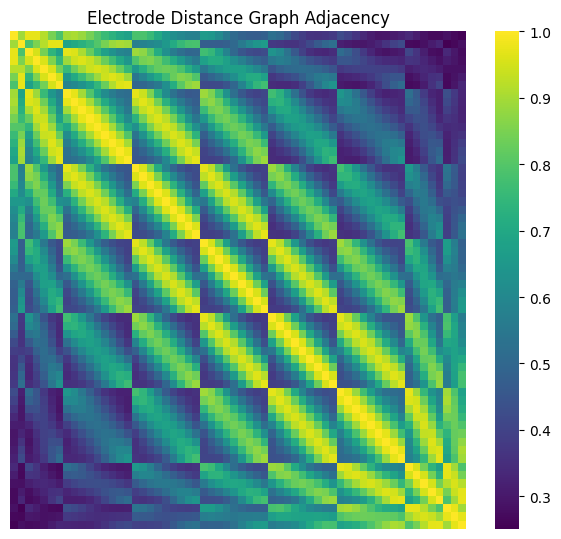

In [3]:
spec = RawEpochSpec(picks=None, bandpass=(4.0, 13.0), resample_sfreq=128.0)
dataset = load_raw_epoch_dataset(paths, task, spec)
X_raw = np.asarray(dataset.X, dtype=np.float32)
y = np.asarray(dataset.y, dtype=np.int64)
subjects = np.asarray(dataset.subjects, dtype=object)
SUBJECT_ID = "P057"
ch_names = list(dataset.channel_names)
sfreq = 128.0

# Build graph spatiotemporal features
bands = {"theta": (5.0, 7.0), "alpha": (8.0, 12.0)}
X_graph, window_centers, band_names = temporal_band_features(
    X_raw,
    sfreq,
    bands=bands,
    window_sec=0.500,
    step_sec=0.100,
    mode="of",
)
adjacency = electrode_distance_adjacency(ch_names, threshold=0.35)

print(f"Raw X: {X_raw.shape} (trials, channels, times)")
print(f"Graph X: {X_graph.shape} (trials, windows, nodes, bands)")
print(f"Bands: {band_names}")
print(f"Adjacency: {adjacency.shape}, density={(adjacency > 0).mean():.3f}")

# Plot adjacency matrix
plt.figure(figsize=(6, 5.5))
sns.heatmap(adjacency, xticklabels=False, yticklabels=False, cmap="viridis")
plt.title("Electrode Distance Graph Adjacency")
plt.tight_layout()
plt.savefig(paths.figures_dir / f"adjacency_{TASK_TAG}.png", dpi=160, bbox_inches="tight")
plt.show()

## ST-GNN Model Definition & Configuration

In [4]:
n_windows = X_graph.shape[1]
n_nodes = X_graph.shape[2]
n_features = X_graph.shape[3]


def make_model():
    return STGNNChebConv(
        n_nodes=n_nodes,
        in_features=n_features,
        adjacency=adjacency,
        n_classes=2,
        cheb_hidden=32,
        temporal_hidden=64,
        K=3,
        dropout=0.4,
    )


train_cfg = TorchTrainConfig(
    epochs=60,
    batch_size=32,
    lr=1e-3,
    weight_decay=1e-4,
    patience=12,
    n_splits=5,
    val_size=0.2,
    random_seed=RANDOM_SEED,
    device=DEVICE,
    progress=True,
)

## 3. Cohort-Wide Training

We train the ST-GNN model across all 24 subjects individually and cache the results.

In [5]:
cohort_metrics_path = paths.tables_dir / f"cohort_cv_metrics_{TASK_TAG}.csv"
cohort_fold_metrics_path = paths.tables_dir / f"cohort_fold_metrics_{TASK_TAG}.csv"
subject_ids = pd.unique(subjects).tolist()

if cohort_metrics_path.exists() and cohort_fold_metrics_path.exists():
    print("Loading ST-GNN cohort metrics from cache...")
    df_cohort = pd.read_csv(cohort_metrics_path)
    df_cohort_folds = pd.read_csv(cohort_fold_metrics_path)
else:
    print("Running ST-GNN cohort-wide cross-validation ...")
    cohort_results = []
    cohort_fold_results = []

    silent_cfg = TorchTrainConfig(
        epochs=train_cfg.epochs,
        batch_size=train_cfg.batch_size,
        lr=train_cfg.lr,
        weight_decay=train_cfg.weight_decay,
        patience=train_cfg.patience,
        n_splits=train_cfg.n_splits,
        val_size=train_cfg.val_size,
        random_seed=train_cfg.random_seed,
        device=train_cfg.device,
        progress=False,
    )

    for sub in subject_ids:
        print(f"Training subject {sub}...")
        stgnn_metrics, _ = cross_validate_torch_model(
            X_graph,
            y,
            make_model,
            silent_cfg,
            subjects=subjects,
            subject_id=sub,
            save_weights_dir=paths.cache_dir,
            weights_prefix=f"{TASK_TAG}_sub{sub}",
            load_weights=True,
        )

        cohort_results.append(
            {
                "subject": sub,
                "stgnn_acc": stgnn_metrics["test_acc"].mean(),
                "stgnn_auc": stgnn_metrics["test_auc"].mean(),
                "stgnn_bal_acc": stgnn_metrics["test_balanced_acc"].mean(),
            }
        )

        for idx, row in stgnn_metrics.iterrows():
            cohort_fold_results.append(
                {
                    "subject": sub,
                    "model": "ST-GNN",
                    "fold": int(row["fold"]),
                    "test_acc": row["test_acc"],
                    "test_auc": row["test_auc"],
                    "test_balanced_acc": row["test_balanced_acc"],
                }
            )

    df_cohort = pd.DataFrame(cohort_results)
    df_cohort.to_csv(cohort_metrics_path, index=False)
    df_cohort_folds = pd.DataFrame(cohort_fold_results)
    df_cohort_folds.to_csv(cohort_fold_metrics_path, index=False)
    print(f"Saved cohort metrics to: {cohort_metrics_path}")

print(df_cohort.describe())

# Global Cohort CV Summary (mean ± std)
print("\n" + "=" * 50)
print("GLOBAL COHORT CROSS-VALIDATION SUMMARY")
print("=" * 50)
for model_name in df_cohort_folds["model"].unique():
    model_df = df_cohort_folds[df_cohort_folds["model"] == model_name]
    print(f"Model: {model_name}")
    for f in sorted(model_df["fold"].unique()):
        fold_df = model_df[model_df["fold"] == f]
        mean_f = fold_df["test_acc"].mean()
        std_f = fold_df["test_acc"].std()
        print(f"  Fold {f} Accuracy: {mean_f:.4f} ± {std_f:.4f}")
    mean_cv = model_df["test_acc"].mean()
    std_cv = model_df["test_acc"].std()
    print(f"  Average CV Accuracy: {mean_cv:.4f} ± {std_cv:.4f}")
print("=" * 50 + "\n")

Running ST-GNN cohort-wide cross-validation ...
Training subject P057...
Filtering to subject P057: 240 epochs
Using torch device: cpu
Fold 1: acc=0.5000, bal_acc=0.5000, auc=0.5675 | fold_time=00:00:03 elapsed_cv=00:00:03 eta_cv=00:00:13
Fold 2: acc=0.6250, bal_acc=0.6250, auc=0.6175 | fold_time=00:00:02 elapsed_cv=00:00:05 eta_cv=00:00:08
Fold 3: acc=0.5000, bal_acc=0.5000, auc=0.6000 | fold_time=00:00:03 elapsed_cv=00:00:08 eta_cv=00:00:05
Fold 4: acc=0.4500, bal_acc=0.4500, auc=0.5250 | fold_time=00:00:02 elapsed_cv=00:00:10 eta_cv=00:00:02
Fold 5: acc=0.4500, bal_acc=0.4500, auc=0.4225 | fold_time=00:00:02 elapsed_cv=00:00:13 eta_cv=00:00:00

SUMMARY METRICS ACROSS FOLDS
Fold 5 Accuracy: 0.4500
Average CV Accuracy: 0.5050 ± 0.0716


OVERALL CROSS-VALIDATION CLASSIFICATION REPORT (AGGREGATED)
              precision    recall  f1-score   support

           0       0.50      0.84      0.63       100
           1       0.52      0.17      0.26       100

    accuracy                

## 4. Single-Subject Detailed Performance Comparison (P057)

=== ST-GNN Classification Report (Subject P057) ===
                  precision    recall  f1-score   support

       Congruent       0.50      0.84      0.63       100
Incongruent_Pure       0.52      0.17      0.26       100

        accuracy                           0.51       200
       macro avg       0.51      0.51      0.44       200
    weighted avg       0.51      0.51      0.44       200



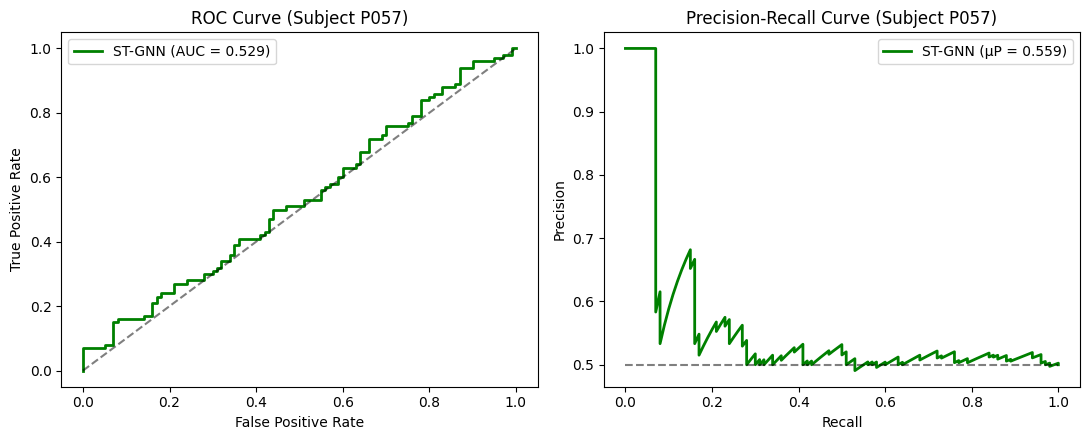

In [ ]:
from br_analysis.torch_training import (
    build_dataloader,
    standardize_train_test,
    _evaluate,
    chronological_group_labels,
    stratified_group_splits,
)

device = torch.device(DEVICE)
splits = list(
    stratified_group_splits(
        y[subjects == SUBJECT_ID],
        groups=chronological_group_labels(int((subjects == SUBJECT_ID).sum())),
        n_splits=train_cfg.n_splits,
    )
)
X_sub = X_graph[subjects == SUBJECT_ID]
y_sub = y[subjects == SUBJECT_ID]

probs = []
y_true_all = []

for fold, (train_idx, test_idx) in enumerate(splits, start=1):
    _, X_test = standardize_train_test(X_sub[train_idx], X_sub[test_idx])
    y_test = y_sub[test_idx]
    y_true_all.extend(y_test)

    model = make_model().to(device)
    model.load_state_dict(
        torch.load(paths.cache_dir / f"{TASK_TAG}_sub{SUBJECT_ID}_fold{fold}.pt", map_location=device), strict=False
    )
    loader = build_dataloader(X_test, y_test, batch_size=train_cfg.batch_size, shuffle=False, device=device)
    _, _, _, p = _evaluate(model, loader, device)
    probs.extend(p)

y_true_all = np.array(y_true_all)
probs = np.array(probs)
preds = (probs >= 0.5).astype(int)

print("=== ST-GNN Classification Report (Subject P057) ===")
print(classification_report(y_true_all, preds, target_names=[task.class_0, task.class_1], zero_division=0.0))

# Plot ROC/PR curves
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.5))
fpr, tpr, _ = roc_curve(y_true_all, probs)
ax_roc.plot(fpr, tpr, label=f"ST-GNN (AUC = {auc(fpr, tpr):.3f})", color="green", linewidth=2)
ax_roc.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax_roc.set_title("ROC Curve (Subject P057)")
ax_roc.set_xlabel("False Positive Rate")
ax_roc.set_ylabel("True Positive Rate")
ax_roc.legend()

prec, rec, _ = precision_recall_curve(y_true_all, probs)
ax_pr.plot(rec, prec, label=f"ST-GNN (μP = {auc(rec, prec):.3f})", color="green", linewidth=2)
ax_pr.plot([0, 1], [0.5, 0.5], "k--", alpha=0.5)
ax_pr.set_title("Precision-Recall Curve (Subject P057)")
ax_pr.set_xlabel("Recall")
ax_pr.set_ylabel("Precision")
ax_pr.legend()

plt.tight_layout()
plt.savefig(paths.figures_dir / f"roc_pr_{TASK_TAG}_P057.png", dpi=180, bbox_inches="tight")
plt.show()

In [ ]:
# Zipping outputs for easy download when running on Kaggle
if IS_KAGGLE:
    import shutil

    print("Zipping outputs...")
    shutil.make_archive("/kaggle/working/outputs", "zip", "/kaggle/working/TFG_Nils_2026/04_Anàlisi")
    print("Zipped outputs saved to /kaggle/working/outputs.zip")

## Final Holdout ONCE

This cell trains the frozen model configuration on each subject's development set and evaluates only the reserved final 20% holdout. The CSV produced here is the only deep-learning result that should feed the thesis final test-set table.

In [ ]:
from br_analysis.torch_training import fit_one_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score

FINAL_TEST_ALREADY_USED = False
final_file = paths.tables_dir / f"final_holdout_{TASK_TAG}.csv"

if final_file.exists():
    print("Loading final holdout results from cache:", final_file)
    df_final_holdout = pd.read_csv(final_file)
elif FINAL_TEST_ALREADY_USED:
    print("FINAL_TEST_ALREADY_USED=True; skipping final holdout evaluation.")
else:
    rows = []
    final_cfg = TorchTrainConfig(
        epochs=train_cfg.epochs,
        batch_size=train_cfg.batch_size,
        lr=train_cfg.lr,
        weight_decay=train_cfg.weight_decay,
        patience=train_cfg.patience,
        n_splits=train_cfg.n_splits,
        val_size=train_cfg.val_size,
        random_seed=train_cfg.random_seed,
        device=train_cfg.device,
        progress=train_cfg.progress,
        refit=True,
    )

    def dev_holdout_idx(n, holdout_frac=0.2):
        cutoff = int(np.floor((1.0 - holdout_frac) * n))
        cutoff = max(1, min(cutoff, n - 1))
        return np.arange(cutoff), np.arange(cutoff, n)

    for sub in subject_ids:
        print(f"Final holdout ST-GNN subject {sub}...")
        mask = subjects == sub
        y_sub = y[mask]
        X_sub = X_graph[mask]
        dev_idx, holdout_idx = dev_holdout_idx(len(y_sub))
        if len(np.unique(y_sub[dev_idx])) < 2 or len(np.unique(y_sub[holdout_idx])) < 2:
            print(f"  Skipping {sub}: holdout lacks both classes")
            continue
        X_dev, X_hold = standardize_train_test(X_sub[dev_idx], X_sub[holdout_idx])
        metrics, _, y_true, probs = fit_one_split(
            make_model,
            X_dev,
            y_sub[dev_idx],
            X_hold,
            y_sub[holdout_idx],
            final_cfg,
            save_path=paths.cache_dir / f"final_holdout_{TASK_TAG}_sub{sub}.pt",
        )
        pred = (probs >= 0.5).astype(int)
        try:
            auc_val = roc_auc_score(y_true, probs)
        except ValueError:
            auc_val = np.nan
        rows.append({
            "Task": task.name,
            "Subject": sub,
            "Model": "ST_GNN",
            "Accuracy": accuracy_score(y_true, pred),
            "Balanced Accuracy": balanced_accuracy_score(y_true, pred),
            "ROC AUC": auc_val,
            "N Test": len(y_true),
            "Source": "final_holdout",
        })
    df_final_holdout = pd.DataFrame(rows)
    df_final_holdout.to_csv(final_file, index=False)
    print("Saved final holdout results to:", final_file)

summary = df_final_holdout.groupby("Model").agg(
    mean_accuracy=("Accuracy", "mean"),
    std_accuracy=("Accuracy", "std"),
    mean_auc=("ROC AUC", "mean"),
    n_subjects=("Subject", "nunique"),
    n_test_trials=("N Test", "sum"),
).reset_index()
print(summary.to_string(index=False))